# Week 2: Exponential and Logarithmic Functions

## SCIE1500 — Analytical Methods for Scientists
### Theme: "Measuring What Grows Without Bound"

---

## Overview

**Science Context:** Bacterial growth, radioactive decay, compound interest, global plastic production, pandemic doubling times

**Learning Outcomes:** By the end of this week you should be able to:
1. Define and evaluate exponential functions $a^x$ and $e^x$
2. Explain why Euler's number $e$ arises from compound interest
3. Use exponential growth and decay models in scientific contexts
4. Define the logarithm as the inverse of the exponential
5. Apply logarithm laws to simplify and solve equations
6. Use the "70 over r" rule to estimate doubling times
7. Work with geometric sequences and series
8. Use Python to plot and analyse exponential and logarithmic data

**Exam Alignment:** Q5, Q6, Q7, Q8

## Setup: Import Required Libraries

Run this cell first to import all the Python libraries we'll use throughout this lesson.

In [1]:
# Standard imports for SCIE1500 notebooks
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import math

# Set plotting style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 12

print("✓ Libraries loaded successfully!")

✓ Libraries loaded successfully!


---

## 1. The Exponential Function

### Why Exponentials?

Linear functions model constant rates of change. But many real-world processes grow or shrink **proportionally to their current size**:
- Bacteria double every 20 minutes → the more there are, the faster they multiply
- Radioactive atoms decay at a rate proportional to the number remaining
- Money in a savings account earns interest on previously earned interest

### General Form

$$f(x) = a^x, \quad a > 0, \; a \neq 1$$

- **Base $a > 1$**: Exponential **growth** (function increases)
- **Base $0 < a < 1$**: Exponential **decay** (function decreases)
- **Domain:** $\mathbb{R}$ (all real numbers)
- **Range:** $(0, \infty)$ — always positive!
- **Key property:** $a^0 = 1$ for any valid base

### Exponential Laws

| Law | Formula |
|-----|---------|
| Product | $a^m \cdot a^n = a^{m+n}$ |
| Quotient | $a^m / a^n = a^{m-n}$ |
| Power | $(a^m)^n = a^{mn}$ |
| Negative | $a^{-n} = 1/a^n$ |
| Fractional | $a^{1/n} = \sqrt[n]{a}$ |

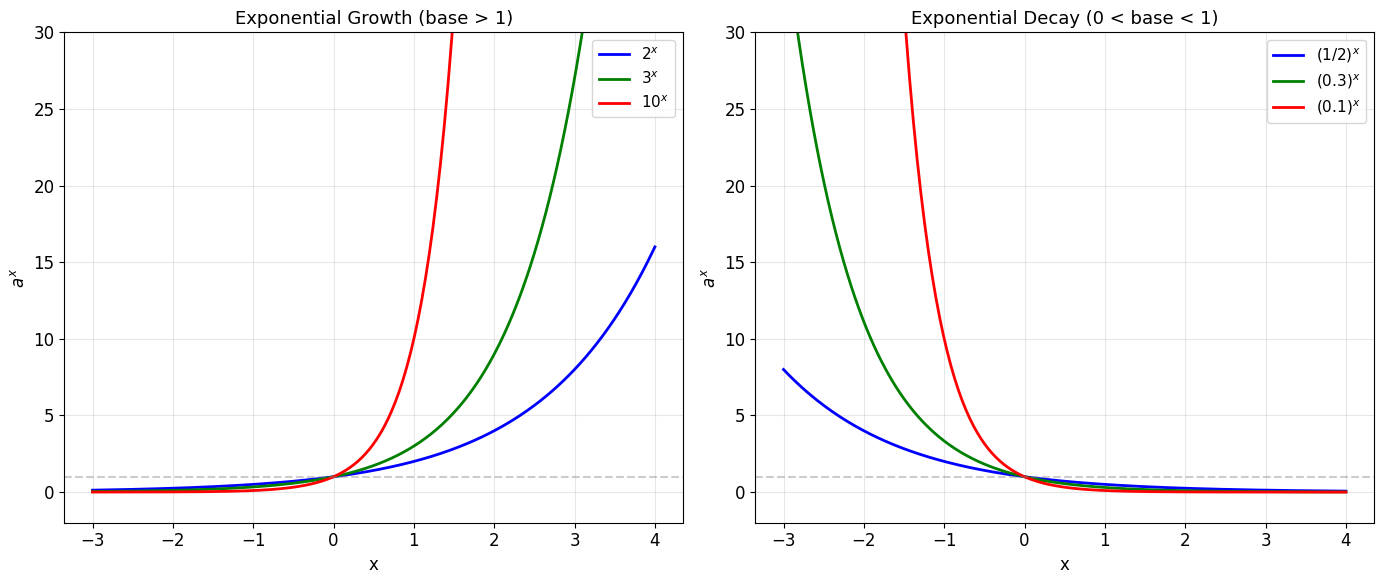

All exponential functions pass through (0, 1) because a⁰ = 1.
Growth curves rise steeply; decay curves approach zero but never reach it.


In [2]:
# Exponential Growth vs Decay

x = np.linspace(-3, 4, 300)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Growth: bases > 1
for base, colour, label in [(2, 'blue', '$2^x$'), (3, 'green', '$3^x$'), (10, 'red', '$10^x$')]:
    ax1.plot(x, base**x, color=colour, linewidth=2, label=label)
ax1.axhline(y=1, color='gray', linestyle='--', alpha=0.4)
ax1.set_xlabel('x', fontsize=12)
ax1.set_ylabel('$a^x$', fontsize=12)
ax1.set_title('Exponential Growth (base > 1)', fontsize=13)
ax1.legend(fontsize=11)
ax1.set_ylim(-2, 30)
ax1.grid(True, alpha=0.3)

# Decay: bases between 0 and 1
for base, colour, label in [(0.5, 'blue', '$(1/2)^x$'), (0.3, 'green', '$(0.3)^x$'), (0.1, 'red', '$(0.1)^x$')]:
    ax2.plot(x, base**x, color=colour, linewidth=2, label=label)
ax2.axhline(y=1, color='gray', linestyle='--', alpha=0.4)
ax2.set_xlabel('x', fontsize=12)
ax2.set_ylabel('$a^x$', fontsize=12)
ax2.set_title('Exponential Decay (0 < base < 1)', fontsize=13)
ax2.legend(fontsize=11)
ax2.set_ylim(-2, 30)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("All exponential functions pass through (0, 1) because a⁰ = 1.")
print("Growth curves rise steeply; decay curves approach zero but never reach it.")

---

## 2. Euler's Number $e$ — The Natural Base

### Discovery Through Compound Interest

Suppose you invest $1 at 100% annual interest. How much do you have after one year?

| Compounding | Formula | Balance |
|-------------|---------|---------|
| Annually (1×) | $(1 + 1/1)^1$ | $2.000 |
| Semi-annually (2×) | $(1 + 1/2)^2$ | $2.250 |
| Quarterly (4×) | $(1 + 1/4)^4$ | $2.441 |
| Monthly (12×) | $(1 + 1/12)^{12}$ | $2.613 |
| Daily (365×) | $(1 + 1/365)^{365}$ | $2.714 |
| Continuously | $\lim_{n \to \infty} (1 + 1/n)^n$ | **$e \approx 2.71828...$** |

This limit defines Euler's number:

$$e = \lim_{n \to \infty} \left(1 + \frac{1}{n}\right)^n \approx 2.71828\ldots$$

### Why $e$ Is Special

The function $f(x) = e^x$ is its own derivative:

$$\frac{d}{dx}e^x = e^x$$

This makes $e^x$ the "natural" choice for modelling continuous growth and decay in science.

Compounding frequency → convergence to e
--------------------------------------------------
  n =       1  (       Annually)  →  2.0000000000
  n =       2  (  Semi-annually)  →  2.2500000000
  n =       4  (      Quarterly)  →  2.4414062500
  n =      12  (        Monthly)  →  2.6130352902
  n =      52  (         Weekly)  →  2.6925969544
  n =     365  (          Daily)  →  2.7145674820
  n =   1,000  (         1,000×)  →  2.7169239322
  n =  10,000  (        10,000×)  →  2.7181459268
  n = 100,000  (       100,000×)  →  2.7182682372

  e (exact)                          →  2.7182818285


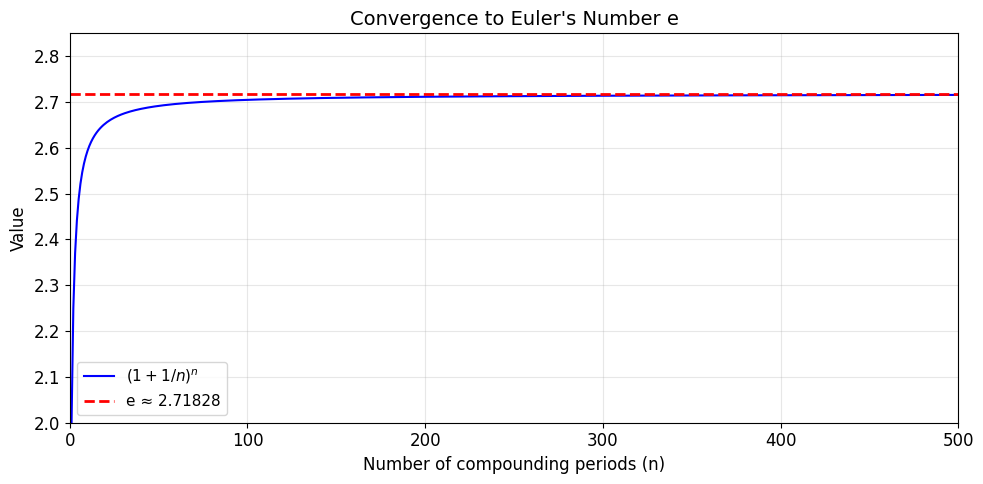

In [3]:
# Compound Interest Convergence to e

n_values = [1, 2, 4, 12, 52, 365, 1000, 10000, 100000]
results = [(1 + 1/n)**n for n in n_values]

print("Compounding frequency → convergence to e")
print("-" * 50)
for n, result in zip(n_values, results):
    label = {1: 'Annually', 2: 'Semi-annually', 4: 'Quarterly',
             12: 'Monthly', 52: 'Weekly', 365: 'Daily',
             1000: '1,000×', 10000: '10,000×', 100000: '100,000×'}
    print(f"  n = {n:>7,}  ({label.get(n, ''):>15s})  →  {result:.10f}")

print(f"\n  e (exact)                          →  {math.e:.10f}")

# Visualise convergence
n_range = np.arange(1, 501)
convergence = [(1 + 1/n)**n for n in n_range]

plt.figure(figsize=(10, 5))
plt.plot(n_range, convergence, 'b-', linewidth=1.5, label='$(1 + 1/n)^n$')
plt.axhline(y=math.e, color='red', linestyle='--', linewidth=2, label=f'e ≈ {math.e:.5f}')
plt.xlabel('Number of compounding periods (n)', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.title('Convergence to Euler\'s Number e', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(0, 500)
plt.ylim(2.0, 2.85)
plt.tight_layout()
plt.show()

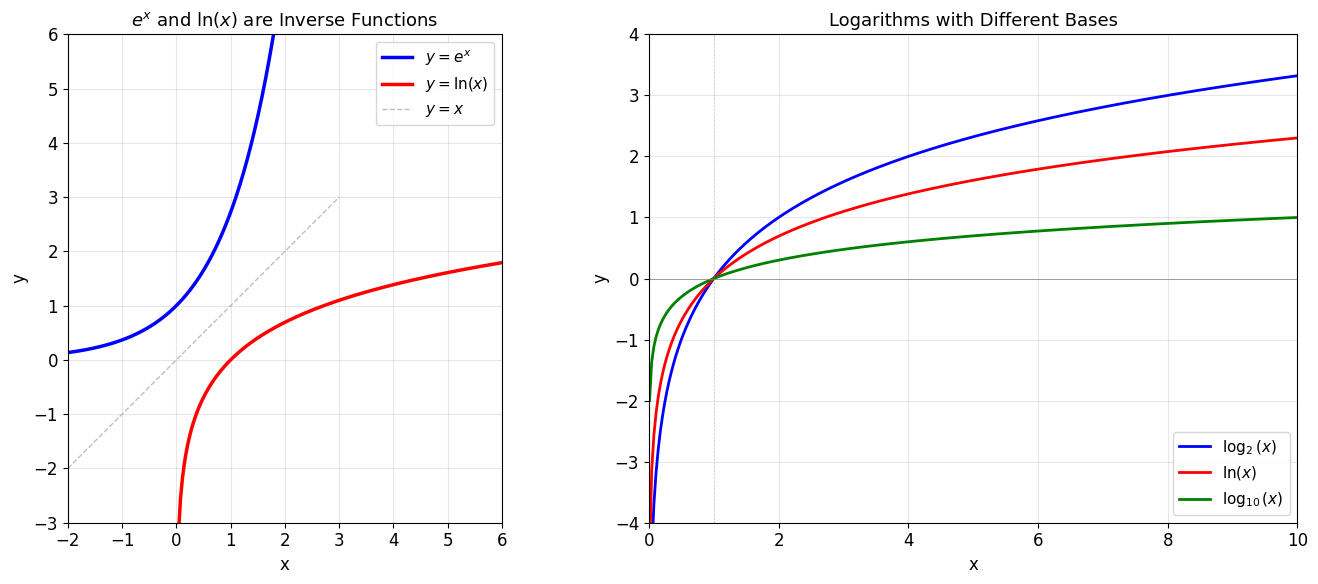

Verifying: ln(eˣ) = x and e^(ln(x)) = x
  ln(e^1) = 1.0000,   e^(ln(1)) = 1.0000
  ln(e^2) = 2.0000,   e^(ln(2)) = 2.0000
  ln(e^5) = 5.0000,   e^(ln(5)) = 5.0000
  ln(e^10) = 10.0000,   e^(ln(10)) = 10.0000


In [4]:
# The Logarithm as the Inverse of the Exponential

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

x_exp = np.linspace(-2, 3, 300)
x_log = np.linspace(0.01, 10, 300)

# Left: exp and ln as mirror images
ax1.plot(x_exp, np.exp(x_exp), 'b-', linewidth=2.5, label='$y = e^x$')
ax1.plot(x_log, np.log(x_log), 'r-', linewidth=2.5, label='$y = \\ln(x)$')
ax1.plot(x_exp, x_exp, 'gray', linewidth=1, linestyle='--', alpha=0.5, label='$y = x$')
ax1.set_xlabel('x', fontsize=12)
ax1.set_ylabel('y', fontsize=12)
ax1.set_title('$e^x$ and $\\ln(x)$ are Inverse Functions', fontsize=13)
ax1.legend(fontsize=11)
ax1.set_xlim(-2, 6)
ax1.set_ylim(-3, 6)
ax1.grid(True, alpha=0.3)
ax1.set_aspect('equal')

# Right: Different log bases
ax2.plot(x_log, np.log2(x_log), 'b-', linewidth=2, label='$\\log_2(x)$')
ax2.plot(x_log, np.log(x_log), 'r-', linewidth=2, label='$\\ln(x)$')
ax2.plot(x_log, np.log10(x_log), 'g-', linewidth=2, label='$\\log_{10}(x)$')
ax2.axhline(y=0, color='gray', linewidth=0.5)
ax2.axvline(x=1, color='gray', linewidth=0.5, linestyle='--', alpha=0.5)
ax2.set_xlabel('x', fontsize=12)
ax2.set_ylabel('y', fontsize=12)
ax2.set_title('Logarithms with Different Bases', fontsize=13)
ax2.legend(fontsize=11)
ax2.set_xlim(0, 10)
ax2.set_ylim(-4, 4)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Verify inverse relationship
print("Verifying: ln(eˣ) = x and e^(ln(x)) = x")
for val in [1, 2, 5, 10]:
    print(f"  ln(e^{val}) = {np.log(np.exp(val)):.4f},   e^(ln({val})) = {np.exp(np.log(val)):.4f}")

---

## 4. Growth and Decay Models

### Exponential Growth Model

$$P(t) = P_0 \cdot e^{rt}$$

- $P_0$: initial quantity at $t = 0$
- $r > 0$: growth rate (as a decimal)
- $t$: time

### Exponential Decay Model

$$A(t) = A_0 \cdot e^{-kt}$$

- $A_0$: initial amount
- $k > 0$: decay constant
- **Half-life:** $t_{1/2} = \frac{\ln 2}{k} \approx \frac{0.693}{k}$

### Example (Bacterial Growth)

A colony starts with 500 bacteria and grows at rate $r = 0.03$ per minute.
- After 1 hour (60 min): $P(60) = 500 \cdot e^{0.03 \times 60} = 500 \cdot e^{1.8} \approx 3024$

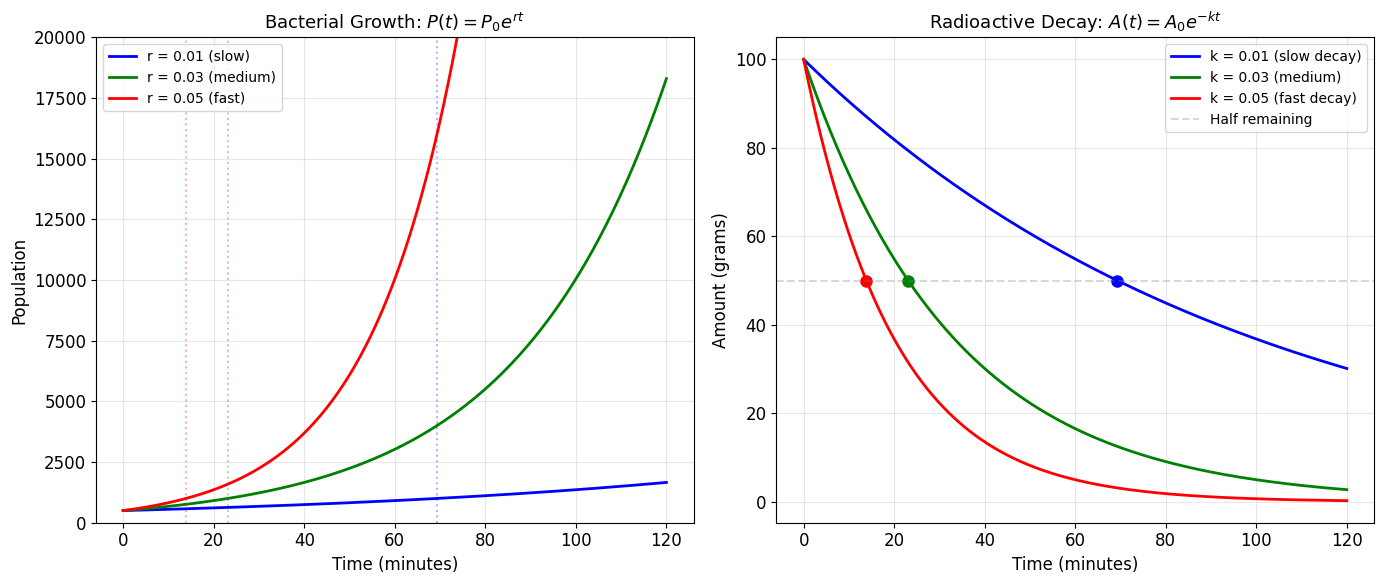

Doubling times (growth):
  r = 0.01:  t_double = ln(2)/0.01 = 69.3 minutes
  r = 0.03:  t_double = ln(2)/0.03 = 23.1 minutes
  r = 0.05:  t_double = ln(2)/0.05 = 13.9 minutes

Half-lives (decay):
  k = 0.01:  t_half = ln(2)/0.01 = 69.3 minutes
  k = 0.03:  t_half = ln(2)/0.03 = 23.1 minutes
  k = 0.05:  t_half = ln(2)/0.05 = 13.9 minutes


In [5]:
# Growth and Decay Models

t = np.linspace(0, 120, 500)  # Time in minutes

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: Bacterial growth at different rates
P0 = 500
for r, colour, label in [(0.01, 'blue', 'r = 0.01 (slow)'),
                          (0.03, 'green', 'r = 0.03 (medium)'),
                          (0.05, 'red', 'r = 0.05 (fast)')]:
    P = P0 * np.exp(r * t)
    ax1.plot(t, P, color=colour, linewidth=2, label=label)
    # Mark doubling time
    t_double = np.log(2) / r
    ax1.axvline(x=t_double, color=colour, linestyle=':', alpha=0.3)

ax1.set_xlabel('Time (minutes)', fontsize=12)
ax1.set_ylabel('Population', fontsize=12)
ax1.set_title('Bacterial Growth: $P(t) = P_0 e^{rt}$', fontsize=13)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 20000)

# Right: Radioactive decay
A0 = 100  # initial mass in grams
for k, colour, label in [(0.01, 'blue', 'k = 0.01 (slow decay)'),
                          (0.03, 'green', 'k = 0.03 (medium)'),
                          (0.05, 'red', 'k = 0.05 (fast decay)')]:
    A = A0 * np.exp(-k * t)
    ax2.plot(t, A, color=colour, linewidth=2, label=label)
    # Mark half-life
    t_half = np.log(2) / k
    ax2.plot(t_half, A0/2, 'o', color=colour, markersize=8)

ax2.axhline(y=50, color='gray', linestyle='--', alpha=0.3, label='Half remaining')
ax2.set_xlabel('Time (minutes)', fontsize=12)
ax2.set_ylabel('Amount (grams)', fontsize=12)
ax2.set_title('Radioactive Decay: $A(t) = A_0 e^{-kt}$', fontsize=13)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate doubling times and half-lives
print("Doubling times (growth):")
for r in [0.01, 0.03, 0.05]:
    print(f"  r = {r}:  t_double = ln(2)/{r} = {np.log(2)/r:.1f} minutes")

print("\nHalf-lives (decay):")
for k in [0.01, 0.03, 0.05]:
    print(f"  k = {k}:  t_half = ln(2)/{k} = {np.log(2)/k:.1f} minutes")

---

## 5. Solving Exponential Equations

### Strategy: "Take the Log of Both Sides"

**Method:** To solve $a^x = b$, take logarithms:
$$x = \frac{\ln(b)}{\ln(a)} = \log_a(b)$$

### Worked Example

**Problem:** A bacterial colony doubles every 3 hours. Starting from 200 bacteria, when will the population reach 10,000?

$$200 \cdot 2^{t/3} = 10000$$
$$2^{t/3} = 50$$
$$\frac{t}{3} = \frac{\ln(50)}{\ln(2)}$$
$$t = 3 \cdot \frac{\ln(50)}{\ln(2)} \approx 16.9 \text{ hours}$$

Problem: 200 · 2^(t/3) = 10,000
When does the colony reach 10,000?

Step 1: Divide both sides by 200
  2^(t/3) = 50.0

Step 2: Take ln of both sides
  (t/3) · ln(2) = ln(50)
  (t/3) · 0.6931 = 3.9120

Step 3: Solve for t
  t = 3 × ln(50)/ln(2)
  t = 3 × 5.6439
  t ≈ 16.93 hours

Verification: P(16.93) = 200 · 2^(16.93/3) = 10000.0 ✓


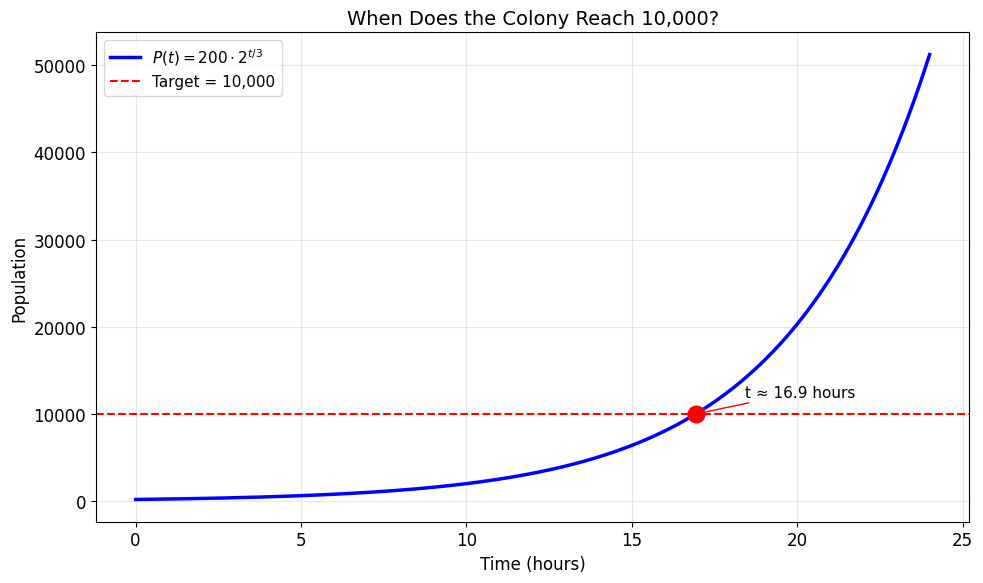

In [6]:
# Solving Exponential Equations with Python

print("=" * 60)
print("Problem: 200 · 2^(t/3) = 10,000")
print("When does the colony reach 10,000?")
print("=" * 60)

# Step-by-step solution
P_initial = 200
P_target = 10000
doubling_period = 3  # hours

# Step 1: Isolate the exponential
ratio = P_target / P_initial
print(f"\nStep 1: Divide both sides by {P_initial}")
print(f"  2^(t/3) = {ratio}")

# Step 2: Take ln of both sides
ln_ratio = np.log(ratio)
ln_2 = np.log(2)
print(f"\nStep 2: Take ln of both sides")
print(f"  (t/3) · ln(2) = ln({ratio:.0f})")
print(f"  (t/3) · {ln_2:.4f} = {ln_ratio:.4f}")

# Step 3: Solve for t
t_solution = doubling_period * ln_ratio / ln_2
print(f"\nStep 3: Solve for t")
print(f"  t = 3 × ln({ratio:.0f})/ln(2)")
print(f"  t = 3 × {ln_ratio/ln_2:.4f}")
print(f"  t ≈ {t_solution:.2f} hours")

# Verify
P_check = P_initial * 2**(t_solution / doubling_period)
print(f"\nVerification: P({t_solution:.2f}) = 200 · 2^({t_solution:.2f}/3) = {P_check:.1f} ✓")

# Visualise
t = np.linspace(0, 24, 300)
P = P_initial * 2**(t / doubling_period)

plt.figure(figsize=(10, 6))
plt.plot(t, P, 'b-', linewidth=2.5, label='$P(t) = 200 \\cdot 2^{t/3}$')
plt.axhline(y=P_target, color='red', linestyle='--', linewidth=1.5, label=f'Target = {P_target:,}')
plt.plot(t_solution, P_target, 'ro', markersize=12, zorder=5)
plt.annotate(f't ≈ {t_solution:.1f} hours', (t_solution, P_target),
             xytext=(t_solution + 1.5, P_target + 2000), fontsize=11,
             arrowprops=dict(arrowstyle='->', color='red'))
plt.xlabel('Time (hours)', fontsize=12)
plt.ylabel('Population', fontsize=12)
plt.title('When Does the Colony Reach 10,000?', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 6. The "70 over r" Rule

### Quick Doubling Time Estimate

For a quantity growing at $r$% per period, the **doubling time** is approximately:

$$t_{double} \approx \frac{70}{r}$$

where $r$ is the percentage growth rate (not decimal).

### Why Does This Work?

From $P_0 \cdot e^{rt} = 2P_0$, we get $t = \frac{\ln 2}{r_{decimal}}$. Since $\ln 2 \approx 0.693$ and $r_{decimal} = r\% / 100$:

$$t = \frac{0.693}{r/100} = \frac{69.3}{r} \approx \frac{70}{r}$$

### Examples

| Growth rate | Rule of 70 estimate | Exact doubling time |
|-------------|--------------------|--------------------|
| 1% per year | 70 years | 69.7 years |
| 3% per year | 23.3 years | 23.1 years |
| 7% per year | 10 years | 10.2 years |

Rate(%)  |  Rule of 70  |  Exact  |  Error (%)
--------------------------------------------------
     1%   |      70.0    |   69.31  |   1.0%
     2%   |      35.0    |   34.66  |   1.0%
     3%   |      23.3    |   23.10  |   1.0%
     4%   |      17.5    |   17.33  |   1.0%
     5%   |      14.0    |   13.86  |   1.0%
     6%   |      11.7    |   11.55  |   1.0%
     7%   |      10.0    |    9.90  |   1.0%
     8%   |       8.8    |    8.66  |   1.0%
     9%   |       7.8    |    7.70  |   1.0%
    10%   |       7.0    |    6.93  |   1.0%
    11%   |       6.4    |    6.30  |   1.0%
    12%   |       5.8    |    5.78  |   1.0%
    13%   |       5.4    |    5.33  |   1.0%
    14%   |       5.0    |    4.95  |   1.0%
    15%   |       4.7    |    4.62  |   1.0%
    16%   |       4.4    |    4.33  |   1.0%
    17%   |       4.1    |    4.08  |   1.0%
    18%   |       3.9    |    3.85  |   1.0%
    19%   |       3.7    |    3.65  |   1.0%
    20%   |       3.5    |    3.47  |   1.0%


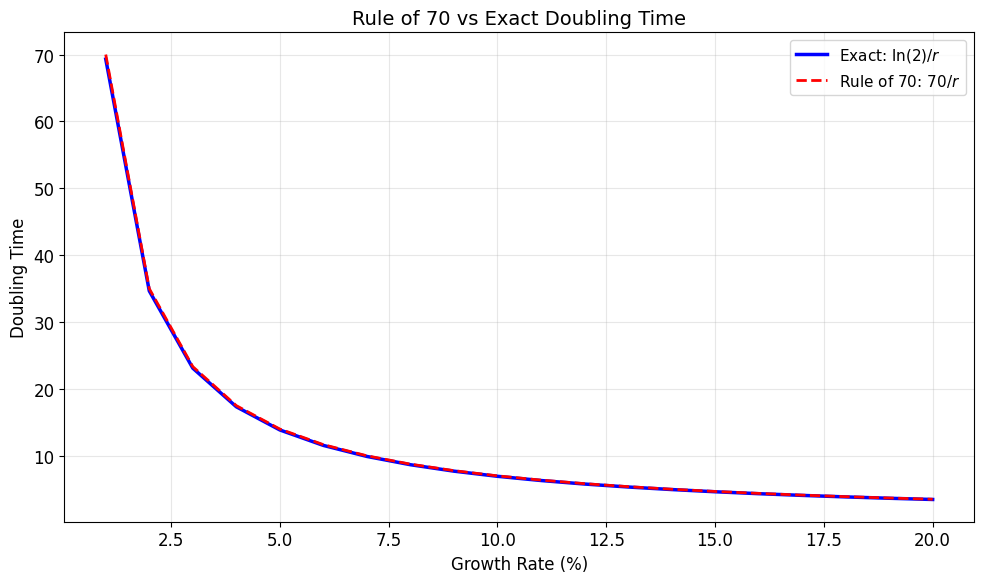


The Rule of 70 is most accurate for small growth rates (1-10%).
For rates above 15%, the error exceeds ~5%.


In [7]:
# The "70 over r" Rule — How Accurate Is It?

rates_percent = np.arange(1, 21)  # 1% to 20%
rule_of_70 = 70 / rates_percent
exact = np.log(2) / (rates_percent / 100)

# Tabulate comparison
print("Rate(%)  |  Rule of 70  |  Exact  |  Error (%)")
print("-" * 50)
for r, r70, ex in zip(rates_percent, rule_of_70, exact):
    error = abs(r70 - ex) / ex * 100
    print(f"  {r:>4d}%   |   {r70:>7.1f}    | {ex:>7.2f}  |   {error:.1f}%")

# Plot comparison
plt.figure(figsize=(10, 6))
plt.plot(rates_percent, exact, 'b-', linewidth=2.5, label='Exact: $\\ln(2)/r$')
plt.plot(rates_percent, rule_of_70, 'r--', linewidth=2, label='Rule of 70: $70/r$')
plt.fill_between(rates_percent, exact, rule_of_70, alpha=0.15, color='red')
plt.xlabel('Growth Rate (%)', fontsize=12)
plt.ylabel('Doubling Time', fontsize=12)
plt.title('Rule of 70 vs Exact Doubling Time', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nThe Rule of 70 is most accurate for small growth rates (1-10%).")
print("For rates above 15%, the error exceeds ~5%.")

---

## 7. Geometric Sequences

### Definition

A **geometric sequence** is one where each term is obtained by multiplying the previous term by a constant ratio $r$:

$$a, \; ar, \; ar^2, \; ar^3, \; \ldots$$

The $n$-th term (starting from $n = 0$):

$$a_n = a \cdot r^n$$

### Geometric Series (Finite Sum)

$$S_n = a + ar + ar^2 + \cdots + ar^{n-1} = a \cdot \frac{r^n - 1}{r - 1}, \quad r \neq 1$$

### Infinite Geometric Series

If $|r| < 1$, the series converges:

$$S_\infty = \frac{a}{1 - r}$$

### Connection to Exponential Functions

A geometric sequence **is** an exponential function sampled at integer points:
$$a_n = a \cdot r^n = a \cdot e^{n \ln r}$$

Geometric sequence: a = 100, r = 0.5
Terms: ['100.0', '50.0', '25.0', '12.5', '6.2', '3.1', '1.6', '0.8', '0.4', '0.2']

Partial sums: ['100.0', '150.0', '175.0', '187.5', '193.8', '196.9', '198.4', '199.2', '199.6', '199.8']
Infinite sum (formula): a/(1-r) = 100/0.5 = 200.0


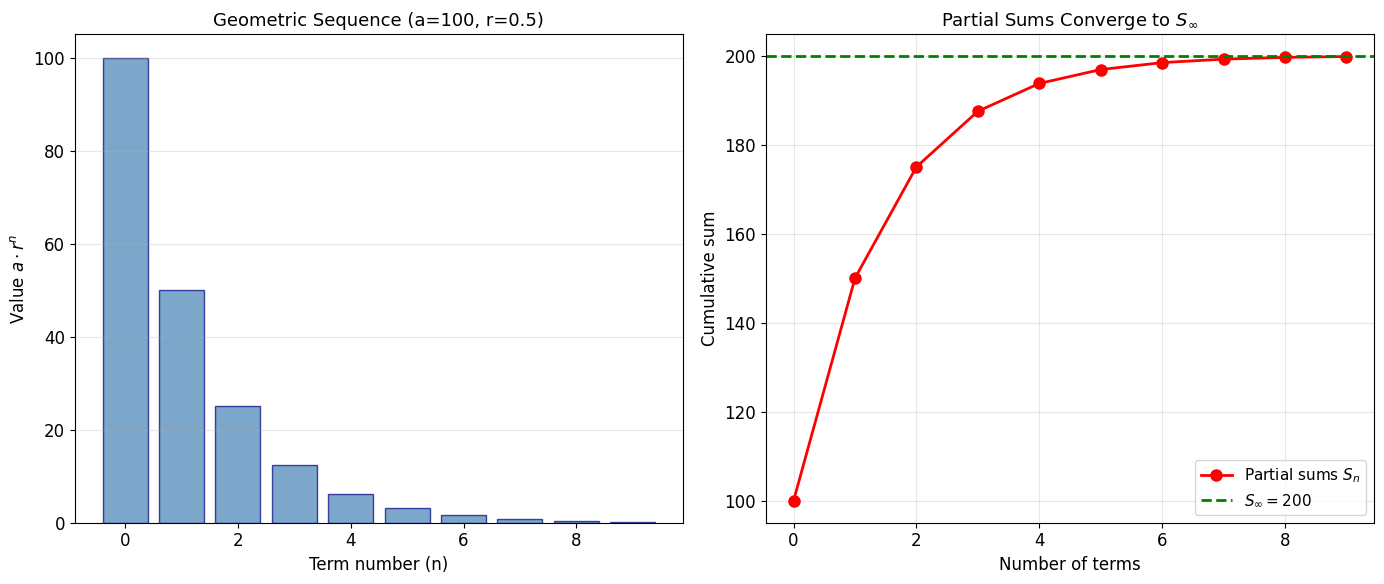


--- Growth Example ---
Investment: $1,000, annual return: 5%
  After  5 years: $1,276
  After 10 years: $1,629
  After 20 years: $2,653
  After 30 years: $4,322


In [8]:
# Geometric Sequences and Series

# Example: Geometric sequence with a=100, r=0.5 (halving)
a = 100
r = 0.5
n_terms = 10
terms = [a * r**n for n in range(n_terms)]

print(f"Geometric sequence: a = {a}, r = {r}")
print(f"Terms: {[f'{t:.1f}' for t in terms]}")

# Partial sums
partial_sums = [sum(terms[:k+1]) for k in range(n_terms)]
print(f"\nPartial sums: {[f'{s:.1f}' for s in partial_sums]}")

# Infinite sum (|r| < 1)
S_inf = a / (1 - r)
print(f"Infinite sum (formula): a/(1-r) = {a}/{1-r} = {S_inf}")

# Visualise
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: Geometric sequence terms
n_vals = np.arange(n_terms)
ax1.bar(n_vals, terms, color='steelblue', alpha=0.7, edgecolor='navy')
ax1.set_xlabel('Term number (n)', fontsize=12)
ax1.set_ylabel('Value $a \\cdot r^n$', fontsize=12)
ax1.set_title(f'Geometric Sequence (a={a}, r={r})', fontsize=13)
ax1.grid(True, alpha=0.3, axis='y')

# Right: Partial sums converging to S_infinity
ax2.plot(n_vals, partial_sums, 'ro-', markersize=8, linewidth=2, label='Partial sums $S_n$')
ax2.axhline(y=S_inf, color='green', linestyle='--', linewidth=2, label=f'$S_\\infty = {S_inf:.0f}$')
ax2.set_xlabel('Number of terms', fontsize=12)
ax2.set_ylabel('Cumulative sum', fontsize=12)
ax2.set_title('Partial Sums Converge to $S_\\infty$', fontsize=13)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Growth example
print("\n--- Growth Example ---")
a_g, r_g = 1000, 1.05  # Investment growing at 5%
print(f"Investment: ${a_g:,}, annual return: {(r_g-1)*100:.0f}%")
for year in [5, 10, 20, 30]:
    value = a_g * r_g**year
    print(f"  After {year:>2d} years: ${value:,.0f}")

---

## 8. Application: Global Plastic Production

### Fitting an Exponential Model

Geyer et al. (2017) reported that global plastic production grew from 2 million tonnes in 1950 to 380 million tonnes by 2015 — a 190× increase in 65 years.

We can model this with:

$$P(t) = 2 \cdot e^{rt}$$

Solving for $r$: $380 = 2 \cdot e^{65r} \Rightarrow r = \frac{\ln(190)}{65} \approx 0.0808$ (8.08% per year)

**Rule of 70 check:** Doubling time $\approx 70/8 \approx 8.75$ years. The data confirms production roughly doubled every 8-9 years from 1950-2015.

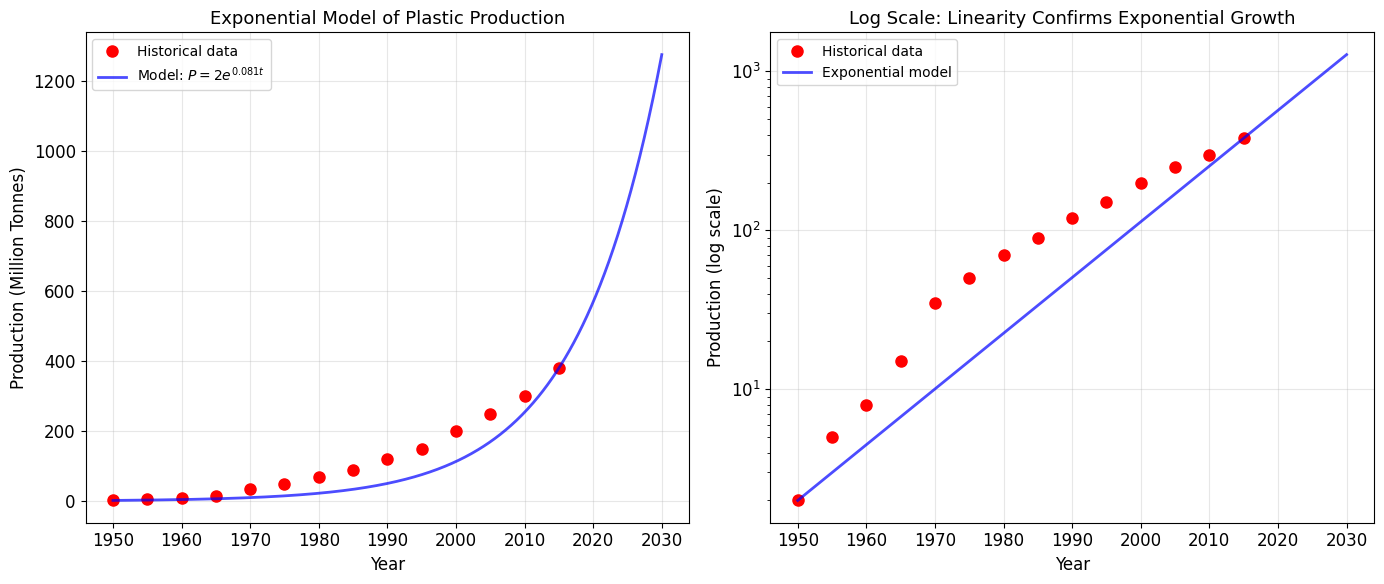

Growth rate: r = 0.0807 (8.07% per year)
Doubling time: 8.6 years
Rule of 70 estimate: 8.7 years

Predictions (extrapolation):
  2020: 569 million tonnes
  2025: 852 million tonnes
  2030: 1275 million tonnes

⚠ Note: Pure exponential growth cannot continue forever.
Physical limits → logistic/bounded growth (see Week 3)


In [9]:
# Global Plastic Production: Exponential Fit

# Historical data (Geyer et al., 2017)
years = np.array([1950, 1955, 1960, 1965, 1970, 1975, 1980, 1985,
                  1990, 1995, 2000, 2005, 2010, 2015])
production = np.array([2, 5, 8, 15, 35, 50, 70, 90,
                       120, 150, 200, 250, 300, 380])

# Fit exponential model
t = years - 1950
P0 = 2
r = np.log(380 / P0) / 65  # growth rate

# Model predictions
t_model = np.linspace(0, 80, 500)
P_model = P0 * np.exp(r * t_model)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: Linear scale
ax1.plot(years, production, 'ro', markersize=8, label='Historical data')
ax1.plot(1950 + t_model, P_model, 'b-', linewidth=2, alpha=0.7, label=f'Model: $P = 2e^{{{r:.3f}t}}$')
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Production (Million Tonnes)', fontsize=12)
ax1.set_title('Exponential Model of Plastic Production', fontsize=13)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Right: Log scale (should be approximately linear)
ax2.semilogy(years, production, 'ro', markersize=8, label='Historical data')
ax2.semilogy(1950 + t_model, P_model, 'b-', linewidth=2, alpha=0.7, label='Exponential model')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Production (log scale)', fontsize=12)
ax2.set_title('Log Scale: Linearity Confirms Exponential Growth', fontsize=13)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
doubling_time = np.log(2) / r
print(f"Growth rate: r = {r:.4f} ({r*100:.2f}% per year)")
print(f"Doubling time: {doubling_time:.1f} years")
print(f"Rule of 70 estimate: {70 / (r*100):.1f} years")
print(f"\nPredictions (extrapolation):")
for yr in [2020, 2025, 2030]:
    pred = P0 * np.exp(r * (yr - 1950))
    print(f"  {yr}: {pred:.0f} million tonnes")
print("\n⚠ Note: Pure exponential growth cannot continue forever.")
print("Physical limits → logistic/bounded growth (see Week 3)")

---

## Key Formulas Summary

| Concept | Formula |
|---------|---------|
| Exponential function | $f(x) = a^x$ ($a > 0$, $a \neq 1$) |
| Euler's number | $e = \lim_{n \to \infty} (1 + 1/n)^n \approx 2.71828$ |
| Slope property of $e^x$ | $\frac{d}{dx} e^x = e^x$ |
| Growth model | $P(t) = P_0 e^{rt}$ |
| Decay model | $A(t) = A_0 e^{-kt}$ |
| Half-life | $t_{1/2} = \ln(2)/k$ |
| Logarithm definition | $\log_a(x) = y \Leftrightarrow a^y = x$ |
| Product law | $\log(AB) = \log A + \log B$ |
| Power law | $\log(A^n) = n \log A$ |
| Rule of 70 | $t_{double} \approx 70/r$ (r in %) |
| Geometric $n$-th term | $a_n = a \cdot r^n$ |
| Geometric series | $S_n = a(r^n - 1)/(r - 1)$ |
| Infinite series ($|r|<1$) | $S_\infty = a/(1 - r)$ |

---

## Self-Assessment Checklist

Before moving to Week 3, ensure you can:

- [ ] Sketch exponential growth ($a > 1$) and decay ($0 < a < 1$) graphs
- [ ] Explain why $e$ arises from continuous compounding
- [ ] Evaluate $\ln(x)$ and apply logarithm laws
- [ ] Set up and solve exponential growth/decay problems
- [ ] Use logarithms to solve equations like $a^x = b$
- [ ] Apply the "70 over r" rule to estimate doubling times
- [ ] Write out terms of a geometric sequence and compute partial sums
- [ ] Determine whether an infinite geometric series converges
- [ ] Use Python to plot exponential functions and verify calculations

---

*Next: Week 3 — Logistic and Bounded Growth Models: When Growth Has Limits*